# Day 3: NLP-Based Customer Review Sentiment Analysis

## Objective

The objective of this analysis is to understand customer feedback from Uber Eats reviews using Natural Language Processing (NLP).

The analysis will:
- Clean and preprocess customer review text.
- Convert text into numerical features using TF-IDF.
- Train a sentiment classification model.
- Evaluate model performance using classification metrics.
- Compare machine learning predictions with VADER sentiment analysis.
- Identify common customer complaints and recommend business improvements.

**Dataset:** `data/raw/reviews.csv`

**Tools:** Python, Pandas, Matplotlib, Scikit-learn, NLTK.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)

PROJECT_DIR = Path.cwd()

if not (PROJECT_DIR / "data" / "raw").exists():
    PROJECT_DIR = Path.home() / "Projects" / "uber-eats-intelligence"

RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
FIGURES_DIR = PROJECT_DIR / "reports" / "figures"
INSIGHTS_DIR = PROJECT_DIR / "reports" / "insights"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
INSIGHTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)

Project directory: /home/nineleaps/Projects/uber-eats-intelligence


In [2]:
reviews = pd.read_csv(RAW_DIR / "reviews.csv")

print("Dataset shape:", reviews.shape)
print("\nColumn names:")
print(reviews.columns.tolist())

print("\nFirst five reviews:")
print(reviews.head())

print("\nDataset information:")
reviews.info()

Dataset shape: (3750, 6)

Column names:
['review_id', 'order_id', 'customer_id', 'restaurant_id', 'review_text', 'sentiment_label']

First five reviews:
   review_id  order_id  customer_id  restaurant_id  \
0          1       311          270             48   
1          2      3594          142              3   
2          3      1595          481             49   
3          4      1660          380             50   
4          5      4799           33             15   

                       review_text sentiment_label  
0  Fresh food and friendly service        Positive  
1    Very disappointing experience        Negative  
2           Delivery was very slow        Negative  
3  Nothing special about the order         Neutral  
4  Fresh food and friendly service        Positive  

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 3750 entries, 0 to 3749
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----

In [3]:
print("Missing values:")
print(reviews.isnull().sum())

print("\nDuplicate rows:", reviews.duplicated().sum())

print("\nSentiment distribution:")
print(reviews["sentiment_label"].value_counts())

print("\nSentiment percentages:")
print(
    (reviews["sentiment_label"].value_counts(normalize=True) * 100)
    .round(2)
)

Missing values:
review_id          0
order_id           0
customer_id        0
restaurant_id      0
review_text        0
sentiment_label    0
dtype: int64

Duplicate rows: 0

Sentiment distribution:
sentiment_label
Positive    2076
Negative     938
Neutral      736
Name: count, dtype: int64

Sentiment percentages:
sentiment_label
Positive    55.36
Negative    25.01
Neutral     19.63
Name: proportion, dtype: float64


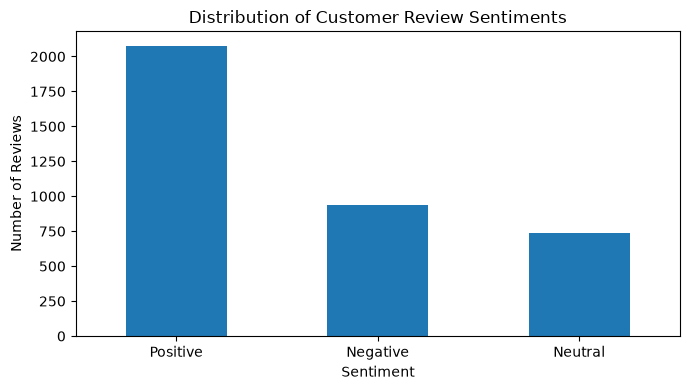

In [4]:
reviews["sentiment_label"].value_counts().plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Distribution of Customer Review Sentiments")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Text Preprocessing

Text preprocessing prepares customer reviews for machine learning. We will remove missing or empty reviews, standardize text to lowercase, and remove unnecessary whitespace.

We will preserve meaningful words such as "not" because they can change the meaning of a review. The original review text will remain available for interpretation.

In [5]:
import re

reviews_clean = reviews.copy()

# Remove rows with missing text or sentiment labels
reviews_clean = reviews_clean.dropna(
    subset=["review_text", "sentiment_label"]
).copy()

# Convert text to strings and normalize it
reviews_clean["review_text"] = (
    reviews_clean["review_text"]
    .astype(str)
    .str.lower()
    .str.strip()
)

# Remove empty reviews
reviews_clean = reviews_clean[
    reviews_clean["review_text"] != ""
].copy()

# Remove duplicate review records
reviews_clean = reviews_clean.drop_duplicates(
    subset=["review_id"]
)

# Standardize sentiment labels
reviews_clean["sentiment_label"] = (
    reviews_clean["sentiment_label"]
    .astype(str)
    .str.strip()
    .str.title()
)

# Retain only the expected sentiment classes
valid_labels = ["Positive", "Neutral", "Negative"]

reviews_clean = reviews_clean[
    reviews_clean["sentiment_label"].isin(valid_labels)
].copy()

print("Original rows:", len(reviews))
print("Cleaned rows:", len(reviews_clean))
print("\nCleaned sentiment distribution:")
print(reviews_clean["sentiment_label"].value_counts())

reviews_clean.to_csv(
    PROCESSED_DIR / "cleaned_reviews.csv",
    index=False
)

Original rows: 3750
Cleaned rows: 3750

Cleaned sentiment distribution:
sentiment_label
Positive    2076
Negative     938
Neutral      736
Name: count, dtype: int64


## TF-IDF and Multinomial Naive Bayes

TF-IDF converts text into numerical features based on how important words are within a review relative to the full collection of reviews.

Multinomial Naive Bayes uses these features to predict whether a review is Positive, Neutral, or Negative.

We will split the data into training and testing sets before fitting TF-IDF. This helps prevent information from the test set leaking into model training.

In [6]:
X = reviews_clean["review_text"]
y = reviews_clean["sentiment_label"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training reviews:", X_train.shape[0])
print("Testing reviews:", X_test.shape[0])
print("TF-IDF training shape:", X_train_tfidf.shape)
print("TF-IDF testing shape:", X_test_tfidf.shape)

Training reviews: 3000
Testing reviews: 750
TF-IDF training shape: (3000, 56)
TF-IDF testing shape: (750, 56)


In [7]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

y_pred = nb_model.predict(X_test_tfidf)

print("Model training completed.")
print("Number of predictions:", len(y_pred))

Model training completed.
Number of predictions: 750


In [8]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

recall = recall_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

f1 = f1_score(
    y_test, y_pred,
    average="weighted",
    zero_division=0
)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy:  1.0000
Precision: 1.0000
Recall:    1.0000
F1-score:  1.0000

Classification Report:
              precision    recall  f1-score   support

    Negative       1.00      1.00      1.00       188
     Neutral       1.00      1.00      1.00       147
    Positive       1.00      1.00      1.00       415

    accuracy                           1.00       750
   macro avg       1.00      1.00      1.00       750
weighted avg       1.00      1.00      1.00       750



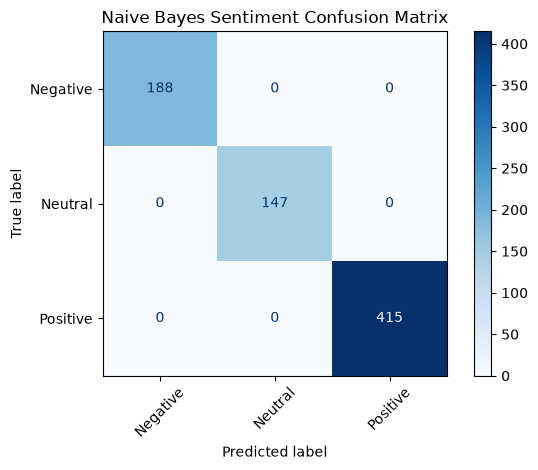

In [9]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"],
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Naive Bayes Sentiment Confusion Matrix")
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "sentiment_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## VADER Sentiment Analysis

VADER is a lexicon- and rule-based sentiment analyzer that estimates sentiment from text. Unlike Naive Bayes, it does not need to be trained on our labeled review dataset.

We will compare VADER's predictions with the dataset's sentiment labels using the same test reviews. This comparison helps us understand the differences between a machine learning classifier and a rule-based approach.

In [10]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [11]:
import nltk
from nltk.sentiment import SentimentIntensityAnalyzer

try:
    vader = SentimentIntensityAnalyzer()
    print("VADER is ready.")
except LookupError:
    nltk.download("vader_lexicon")
    vader = SentimentIntensityAnalyzer()
    print("VADER lexicon downloaded. VADER is ready.")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /home/nineleaps/nltk_data...


VADER lexicon downloaded. VADER is ready.


In [12]:
def vader_sentiment(text):
    scores = vader.polarity_scores(text)
    compound = scores["compound"]

    if compound >= 0.05:
        return "Positive"
    elif compound <= -0.05:
        return "Negative"
    else:
        return "Neutral"


vader_pred = X_test.apply(vader_sentiment)

vader_accuracy = accuracy_score(y_test, vader_pred)

vader_precision = precision_score(
    y_test, vader_pred,
    average="weighted",
    zero_division=0
)

vader_recall = recall_score(
    y_test, vader_pred,
    average="weighted",
    zero_division=0
)

vader_f1 = f1_score(
    y_test, vader_pred,
    average="weighted",
    zero_division=0
)

print(f"VADER Accuracy:  {vader_accuracy:.4f}")
print(f"VADER Precision: {vader_precision:.4f}")
print(f"VADER Recall:    {vader_recall:.4f}")
print(f"VADER F1-score:  {vader_f1:.4f}")

VADER Accuracy:  0.6867
VADER Precision: 0.7227
VADER Recall:    0.6867
VADER F1-score:  0.7009


In [13]:
model_comparison = pd.DataFrame({
    "Model": ["TF-IDF + Naive Bayes", "VADER"],
    "Accuracy": [accuracy, vader_accuracy],
    "Precision": [precision, vader_precision],
    "Recall": [recall, vader_recall],
    "F1_Score": [f1, vader_f1]
})

print(model_comparison.round(4))

model_comparison.to_csv(
    INSIGHTS_DIR / "sentiment_model_comparison.csv",
    index=False
)

                  Model  Accuracy  Precision  Recall  F1_Score
0  TF-IDF + Naive Bayes    1.0000     1.0000  1.0000    1.0000
1                 VADER    0.6867     0.7227  0.6867    0.7009


## Customer Complaint and Review Themes

The purpose of this section is to identify recurring topics in customer feedback. We will examine negative reviews and use word frequencies to find commonly occurring terms.

Frequent words provide an initial indication of possible issues. They do not prove the underlying cause, so findings should be validated by reviewing individual comments and, where available, order and delivery information.

In [14]:
negative_reviews = reviews_clean[
    reviews_clean["sentiment_label"] == "Negative"
].copy()

print("Number of negative reviews:", len(negative_reviews))

print("\nSample negative reviews:")
print(negative_reviews["review_text"].head(10).to_string(index=False))

Number of negative reviews: 938

Sample negative reviews:
 very disappointing experience
        delivery was very slow
        delivery was very slow
 very disappointing experience
       order was missing items
poor packaging and bad service
 very disappointing experience
        delivery was very slow
 very disappointing experience
 very disappointing experience


              word_or_phrase  frequency
12                     order        202
9                      items        202
11             missing items        202
10                   missing        202
13             order missing        202
6                 experience        191
2                   delivery        191
3              delivery slow        191
19                      slow        191
4              disappointing        191
5   disappointing experience        191
1                bad service        188
0                        bad        188
16                      poor        188
15             packaging bad        188
14                 packaging        188
17            poor packaging        188
18                   service        188
8               food arrived        166
7                       food        166


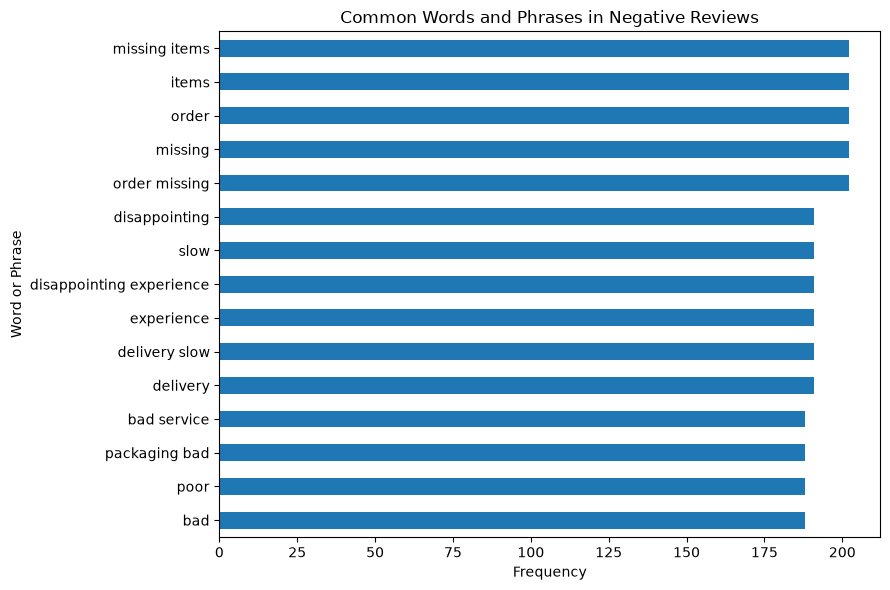

In [15]:
from sklearn.feature_extraction.text import CountVectorizer

if len(negative_reviews) > 0:
    complaint_vectorizer = CountVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        max_features=20
    )

    complaint_matrix = complaint_vectorizer.fit_transform(
        negative_reviews["review_text"]
    )

    word_counts = np.asarray(
        complaint_matrix.sum(axis=0)
    ).ravel()

    complaint_words = pd.DataFrame({
        "word_or_phrase": complaint_vectorizer.get_feature_names_out(),
        "frequency": word_counts
    }).sort_values(
        "frequency", ascending=False
    )

    print(complaint_words.head(20))

    complaint_words.to_csv(
        INSIGHTS_DIR / "negative_review_themes.csv",
        index=False
    )

    complaint_words.head(15).sort_values(
        "frequency"
    ).plot(
        x="word_or_phrase",
        y="frequency",
        kind="barh",
        legend=False,
        figsize=(9, 6)
    )

    plt.title("Common Words and Phrases in Negative Reviews")
    plt.xlabel("Frequency")
    plt.ylabel("Word or Phrase")
    plt.tight_layout()

    plt.savefig(
        FIGURES_DIR / "negative_review_themes.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
else:
    print("No negative reviews found. Check the sentiment labels.")

In [16]:
test_results = pd.DataFrame({
    "review_text": X_test.values,
    "actual_sentiment": y_test.values,
    "naive_bayes_prediction": y_pred,
    "vader_prediction": vader_pred.values
})

test_results.to_csv(
    PROCESSED_DIR / "sentiment_predictions.csv",
    index=False
)

print("Saved sentiment predictions.")
print("Saved model comparison to:", INSIGHTS_DIR)

Saved sentiment predictions.
Saved model comparison to: /home/nineleaps/Projects/uber-eats-intelligence/reports/insights


In [18]:
import joblib

models_dir = PROJECT_DIR / "models"
models_dir.mkdir(parents=True, exist_ok=True)

print("Saving sentiment model...")

joblib.dump(
    nb_model,
    models_dir / "sentiment_nb_model.joblib"
)

print("Saving TF-IDF vectorizer...")

joblib.dump(
    tfidf,
    models_dir / "sentiment_tfidf_vectorizer.joblib"
)

print("Both files saved successfully!")
print("Model file exists:",
      (models_dir / "sentiment_nb_model.joblib").exists())
print("Vectorizer file exists:",
      (models_dir / "sentiment_tfidf_vectorizer.joblib").exists())

Saving sentiment model...
Saving TF-IDF vectorizer...
Both files saved successfully!
Model file exists: True
Vectorizer file exists: True


## Example Sentiment Predictions

In this section, we will examine sample customer reviews alongside their actual sentiment labels and the predictions generated by Naive Bayes and VADER. This helps us understand how the two approaches classify customer feedback.

In [19]:
# Compare actual labels with both model predictions
comparison_samples = test_results[
    [
        "review_text",
        "actual_sentiment",
        "naive_bayes_prediction",
        "vader_prediction"
    ]
].head(10)

print(comparison_samples.to_string(index=False))

                     review_text actual_sentiment naive_bayes_prediction vader_prediction
 fresh food and friendly service         Positive               Positive         Positive
      food arrived cold and late         Negative               Negative          Neutral
    great food and fast delivery         Positive               Positive         Positive
            very good experience         Positive               Positive         Positive
excellent service and tasty food         Positive               Positive         Positive
          service was acceptable          Neutral                Neutral         Positive
excellent service and tasty food         Positive               Positive         Positive
   very disappointing experience         Negative               Negative         Negative
excellent service and tasty food         Positive               Positive         Positive
            very good experience         Positive               Positive         Positive


## Business Insights and Recommendations

### Sentiment Analysis Findings

The Naive Bayes model classifies customer reviews into positive, neutral, and negative sentiment categories using TF-IDF features. VADER provides a second, rule-based approach for comparison.

The final findings will be based on the actual accuracy, precision, recall, and F1-score results produced by both approaches.

### Business Recommendations

- **Negative feedback:** Investigate recurring issues identified in negative reviews.
- **Delivery experience:** If reviews frequently mention delays, examine delivery times and operational bottlenecks.
- **Food quality:** If food quality concerns occur frequently, review restaurant quality and packaging processes.
- **Customer satisfaction:** Monitor sentiment trends over time and investigate changes in negative feedback.
- **Model evaluation:** Use the confusion matrix and classification metrics to identify sentiment classes that require better prediction.

### Limitations

The review dataset is synthetically generated. Consequently, model performance and identified themes may not represent actual customer behavior. Sentiment labels in the dataset may also be easier to predict than labels from real-world reviews. The model should be tested on genuine, independently labeled customer feedback before operational use.

In [20]:
evaluation_metrics = pd.DataFrame({
    "Model": ["TF-IDF + Naive Bayes", "VADER"],
    "Accuracy": [accuracy, vader_accuracy],
    "Weighted_Precision": [precision, vader_precision],
    "Weighted_Recall": [recall, vader_recall],
    "Weighted_F1_Score": [f1, vader_f1]
})

evaluation_metrics.to_csv(
    INSIGHTS_DIR / "sentiment_evaluation_metrics.csv",
    index=False
)

print(evaluation_metrics.round(4))
print("\nSaved sentiment_evaluation_metrics.csv")

                  Model  Accuracy  Weighted_Precision  Weighted_Recall  \
0  TF-IDF + Naive Bayes    1.0000              1.0000           1.0000   
1                 VADER    0.6867              0.7227           0.6867   

   Weighted_F1_Score  
0             1.0000  
1             0.7009  

Saved sentiment_evaluation_metrics.csv


In [21]:
required_files = [
    PROCESSED_DIR / "cleaned_reviews.csv",
    PROCESSED_DIR / "sentiment_predictions.csv",
    FIGURES_DIR / "sentiment_distribution.png",
    FIGURES_DIR / "sentiment_confusion_matrix.png",
    FIGURES_DIR / "negative_review_themes.png",
    INSIGHTS_DIR / "sentiment_model_comparison.csv",
    INSIGHTS_DIR / "sentiment_evaluation_metrics.csv",
    PROJECT_DIR / "models" / "sentiment_nb_model.joblib",
    PROJECT_DIR / "models" / "sentiment_tfidf_vectorizer.joblib"
]

for file_path in required_files:
    status = "FOUND" if file_path.exists() else "MISSING"
    print(f"{status}: {file_path.relative_to(PROJECT_DIR)}")

FOUND: data/processed/cleaned_reviews.csv
FOUND: data/processed/sentiment_predictions.csv
FOUND: reports/figures/sentiment_distribution.png
FOUND: reports/figures/sentiment_confusion_matrix.png
FOUND: reports/figures/negative_review_themes.png
FOUND: reports/insights/sentiment_model_comparison.csv
FOUND: reports/insights/sentiment_evaluation_metrics.csv
FOUND: models/sentiment_nb_model.joblib
FOUND: models/sentiment_tfidf_vectorizer.joblib
